[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SinaGhanbarii/gasmem/blob/main/notebooks/11_your_own_data.ipynb)

# 11 · Compare the models with your own data

If you have measurements from a module (laboratory, pilot or plant), you can check the models
against them in a few lines, and fit permeances to them.

1. Get a blank data sheet with `template`, fill it in (one row per operating point).
2. `compare` runs the model at every point and pairs each prediction with its measurement.
3. `fit_permeances` finds the permeances that best reproduce your data.

**Please share what you find.** Comparisons with real modules are the most useful contribution to
this toolkit, whether the agreement is good or poor. See *Sharing your comparison* at the end.

In [1]:
\
# --- Find the toolkit (works on your own computer and in Google Colab) ---
import sys, os, glob, pathlib

def _find_toolkit():
    here = pathlib.Path.cwd()
    for p in [here, *here.parents]:                       # running from inside the folder
        if (p / "gasmem" / "__init__.py").exists():
            return p
    for pat in ["/content/*/gasmem/__init__.py",           # Colab: repository cloned into /content
                "/content/drive/MyDrive/gasmem/__init__.py",
                "/content/drive/MyDrive/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/gasmem/__init__.py",
                "/content/drive/MyDrive/*/*/*/gasmem/__init__.py"]:
        hits = sorted(glob.glob(pat))
        if hits:
            return pathlib.Path(hits[0]).parents[1]
    return None

TOOLKIT = _find_toolkit()
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO = "https://github.com/SinaGhanbarii/gasmem.git"
if TOOLKIT is None and IN_COLAB:
    # opened from the "Open in Colab" badge: fetch the toolkit from GitHub
    import subprocess
    print("Downloading the toolkit from", REPO)
    if subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/gasmem"]).returncode:
        print("Download failed; looking in your Google Drive instead (approve the access request)")
        from google.colab import drive
        drive.mount("/content/drive")
    TOOLKIT = _find_toolkit()
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()               # makes the sliders work in Colab
if TOOLKIT is None:
    raise FileNotFoundError("Could not find the 'gasmem' folder. Open this notebook from inside "
                            "your copy of the repository (git clone " + REPO + ").")
sys.path.insert(0, str(TOOLKIT))
os.chdir(TOOLKIT / "notebooks")
print("Using toolkit at", TOOLKIT)
# ---------------------------------------------------------------------------

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as w
from IPython.display import display, Markdown
from gasmem import *
import gasmem.plotting as gasmem_plot
from gasmem.plotting import (plot_stage_cut_tradeoff, plot_purity_recovery, plot_profiles,
                             bar_breakdown, COLORS, MARKERS)
pd.set_option("display.precision", 4)

Using toolkit at /home/claude/gas-membrane-stagecut-toolkit


In [2]:
from gasmem.userdata import template, read, compare, fit_permeances
template(["O2", "N2"])

,point,pattern,p_feed_bar,p_perm_bar,feed_flow_mol_s,x_feed_O2,x_feed_N2,stage_cut,area_m2,y_perm_O2,y_perm_N2,x_ret_O2,x_ret_N2
0,P1,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,P2,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,P3,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


| Column | Meaning |
|---|---|
| `point` | your label for the operating point |
| `pattern` | optional per row; otherwise the `pattern` argument |
| `p_feed_bar`, `p_perm_bar` | absolute pressures, bar |
| `feed_flow_mol_s` (or `feed_flow_Nm3h`) | needed to compare areas, or to rate a module |
| `x_feed_<comp>` | feed mole fractions |
| `stage_cut` | measured stage cut: the model runs at it (**design mode**) |
| `area_m2` | membrane area: compared in design mode, or used to predict the stage cut (**rating mode**) |
| `y_perm_<comp>`, `x_ret_<comp>` | measured permeate and retentate mole fractions |

Use fractions, not percent, and leave cells empty when a quantity was not measured.

## Worked example

As an example, the measured points of Feng et al. (1999), Figs. 4–5 (air separation, bore-side
feed, counter-current, 7.83 bar feed, 0.93 bar permeate) are put into the sheet format. These are
digitised values shipped with the toolkit; replace them with your own file, e.g.
`data = read("my_module.csv")`.

In [3]:
from gasmem.datasets import load
feng = load("Feng1999").query("figure in ['Fig. 4', 'Fig. 5'] and "
                              "series == 'bore-side feed, countercurrent'")
rows = []
for _, p in feng.iterrows():
    row = {"point": f"{p.figure}, θ={p.x:.3f}", "p_feed_bar": 7.828, "p_perm_bar": 0.933,
           "x_feed_O2": 0.205, "x_feed_N2": 0.795, "stage_cut": p.x}
    row["x_ret_N2" if "N2" in p.quantity else "y_perm_O2"] = p.y / 100
    rows.append(row)
data = pd.DataFrame(rows)
data.to_csv("example_user_data.csv", index=False)      # this is what your file would look like
read("example_user_data.csv").head()

,point,p_feed_bar,p_perm_bar,x_feed_O2,x_feed_N2,stage_cut,x_ret_N2,y_perm_O2
0,"Fig. 4, θ=0.848",7.828,0.933,0.205,0.795,0.8479,0.9940,NaN
1,"Fig. 4, θ=0.783",7.828,0.933,0.205,0.795,0.7826,0.9936,NaN
2,"Fig. 4, θ=0.705",7.828,0.933,0.205,0.795,0.7053,0.9879,NaN
3,"Fig. 4, θ=0.613",7.828,0.933,0.205,0.795,0.6131,0.9743,NaN
4,"Fig. 4, θ=0.598",7.828,0.933,0.205,0.795,0.5981,0.9722,NaN


## Compare

,,points,bias,rms,max_abs,rms_relative_%
quantity,unit,,,,,
permeate O2,mol%,12,0.1324,0.2859,0.5614,0.8850
retentate N2,mol%,12,0.2397,0.3577,0.5427,0.3708


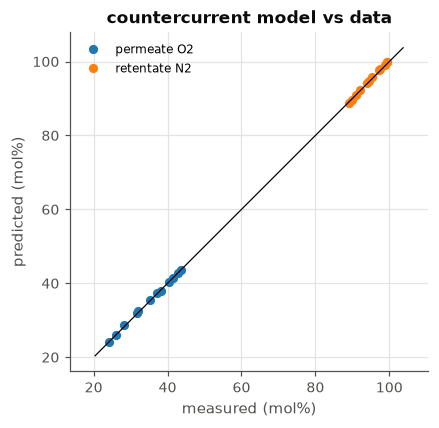

In [4]:
m = Membrane(MEMBRANE_PRESETS["Asymmetric hollow fibre air (Feng 1999)"])
cmp = compare(m, "example_user_data.csv", pattern="countercurrent")
display(cmp.summary())
cmp.plot();

`cmp.table` holds every pair (point, quantity, measured, predicted, error) for your own plots, and
`cmp.failed` lists any point the model could not run, with the reason.

## Fit permeances

Compositions depend only on permeance *ratios*, so without area data the fit returns the
selectivity, with the fastest gas held at its starting value. Here the fit starts from a poor guess,
α = 3, to show that the data, not the preset, fix the answer.

In [5]:
start = Membrane({"O2": 9.2, "N2": 9.2 / 3})
fitted, cmp_fit, info = fit_permeances(start, "example_user_data.csv", pattern="countercurrent")
print(fitted)
print("fitted O2/N2 selectivity:", round(fitted.selectivity("O2", "N2"), 3),
      " (preset from Feng's paper:", round(m.selectivity("O2", "N2"), 3), ")")
print(info["note"])
print("95 % range:", info.get("permeance_95pct_range_GPU"))
cmp_fit.summary()

Membrane('membrane (fitted)': O2=9.2, N2=1.725 GPU)
fitted O2/N2 selectivity: 5.334  (preset from Feng's paper: 5.4 )
no area data: O2 held at 9.2 GPU, selectivities fitted
95 % range: {'N2': (1.693310889356182, 1.7570713160051898)}


,,points,bias,rms,max_abs,rms_relative_%
quantity,unit,,,,,
permeate O2,mol%,12,0.0509,0.2950,0.5160,0.8743
retentate N2,mol%,12,0.1775,0.3292,0.5375,0.3427


If your sheet has areas and feed flows, both permeances are fitted, and the result is the effective
permeance of your module (which includes any effects the model leaves out). Try other flow patterns
too: the pattern that fits best tells you how your module behaves (Pan 1986 found cross-flow for
high-flux asymmetric fibres).

## Sharing your comparison

Open an issue on GitHub (https://github.com/SinaGhanbarii/gasmem/issues) with:

* the data sheet (CSV), or the summary table if the data are confidential;
* the membrane (or permeances), module type and flow pattern you assumed;
* `cmp.summary()` and the parity plot;
* where the data come from (paper, own measurements) and whether it may be added to the toolkit's
  validation set, with credit.

Poor agreement is just as useful as good agreement: it shows where the models need work.